<a href="https://colab.research.google.com/github/tqd3pz/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anastacia Oliynyk, Emma Chung, Kevin Sun

**Date:** 11/16/26

In [37]:
# Your Phase 1 solution to the problem goes here.

In [38]:
# Q1

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score

heart_failure = pd.read_csv("heart_failure_clinical_records_dataset.csv")
heart_failure.columns = heart_failure.columns.str.strip().str.lower()

print("Original shape:", heart_failure.shape)
display(heart_failure.head())
heart_failure.info()
display(heart_failure.describe().round(2))

print("Missing values per column:")
print(heart_failure.isna().sum())
print("Duplicate rows:", heart_failure.duplicated().sum())

heart_failure = heart_failure.dropna().drop_duplicates()
print("Cleaned shape:", heart_failure.shape)
print(heart_failure["death_event"].value_counts())

X = heart_failure.drop(columns=["death_event", "time"])
y = heart_failure["death_event"]

Original shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  death_event               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26,0.32
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61,0.47
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00,0.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00,0.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00,0.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00,1.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00,1.00


Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
death_event                 0
dtype: int64
Duplicate rows: 0
Cleaned shape: (299, 13)
death_event
0    203
1     96
Name: count, dtype: int64


I kept all 299 rows because there were no missing values or duplicate rows. death_event was used as the outcome and time was excluded because follow-up length is only known after baseline.

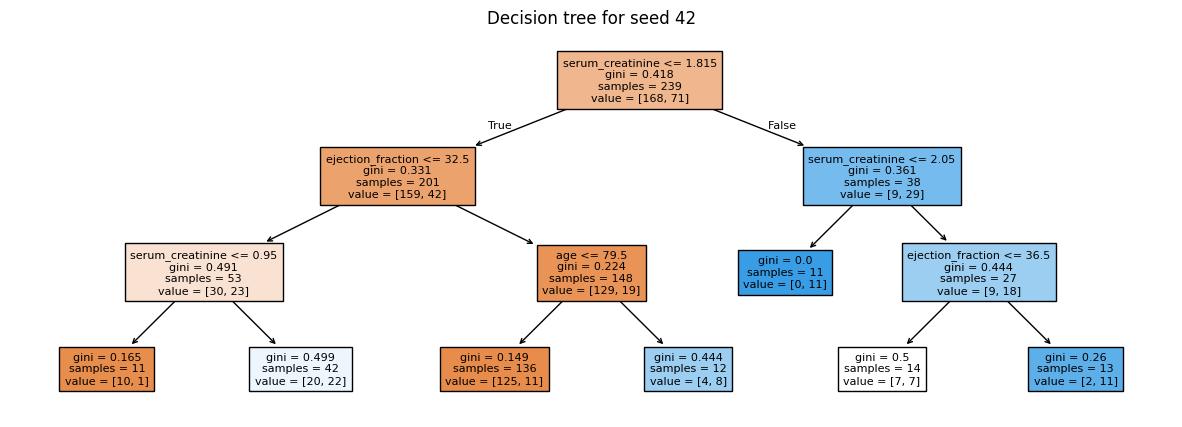

Training rows: 239
Test rows: 60


,Tree accuracy (%),Linear accuracy (%)
Seed,,
42,73.3,66.7


,Actual,Tree score,Linear score
281,0,0.846154,0.499883
265,0,0.080882,0.074459
164,1,0.523810,0.147295
9,1,0.500000,1.577638
77,0,0.080882,-0.043528


In [39]:
# Q2

baseline_seed = 42
X_train, X_q2_test, y_train, y_q2_test = train_test_split(
    X, y, test_size=0.20, random_state=baseline_seed
)

test_predictions = {}
accuracy_by_seed = {}
coefficients = {}
tree_scores = pd.DataFrame(index=X_q2_test.index)
linear_scores = pd.DataFrame(index=X_q2_test.index)

def fit_and_save(seed, X_train, X_test, y_train, y_test):
    tree = DecisionTreeClassifier(max_depth=3, random_state=42)
    tree.fit(X_train, y_train)

    linear = LinearRegression()
    linear.fit(X_train, y_train)

    tree_test = tree.predict_proba(X_test)[:, 1]
    linear_test = linear.predict(X_test)
    linear_classes = (linear_test >= 0.5).astype(int)

    test_predictions[seed] = pd.DataFrame({
        "Actual": y_test,
        "Tree score": tree_test,
        "Linear score": linear_test
    }, index=X_test.index)

    accuracy_by_seed[seed] = {
        "Tree accuracy (%)": 100 * accuracy_score(y_test, tree.predict(X_test)),
        "Linear accuracy (%)": 100 * accuracy_score(y_test, linear_classes)
    }

    coef = pd.Series(linear.coef_, index=X.columns)
    coef.loc["Intercept"] = linear.intercept_
    coefficients[seed] = coef

    # Score the seed 42 test patients for the Q4 comparison.
    tree_scores[seed] = tree.predict_proba(X_q2_test)[:, 1]
    linear_scores[seed] = linear.predict(X_q2_test)

    plt.figure(figsize=(15, 5))
    plot_tree(tree, feature_names=X.columns.tolist(), filled=True, fontsize=8)
    plt.title(f"Decision tree for seed {seed}")
    plt.show()

fit_and_save(baseline_seed, X_train, X_q2_test, y_train, y_q2_test)
print("Training rows:", len(X_train))
print("Test rows:", len(X_q2_test))
display(pd.DataFrame(accuracy_by_seed).T.rename_axis("Seed").round(1))
display(test_predictions[baseline_seed].head())

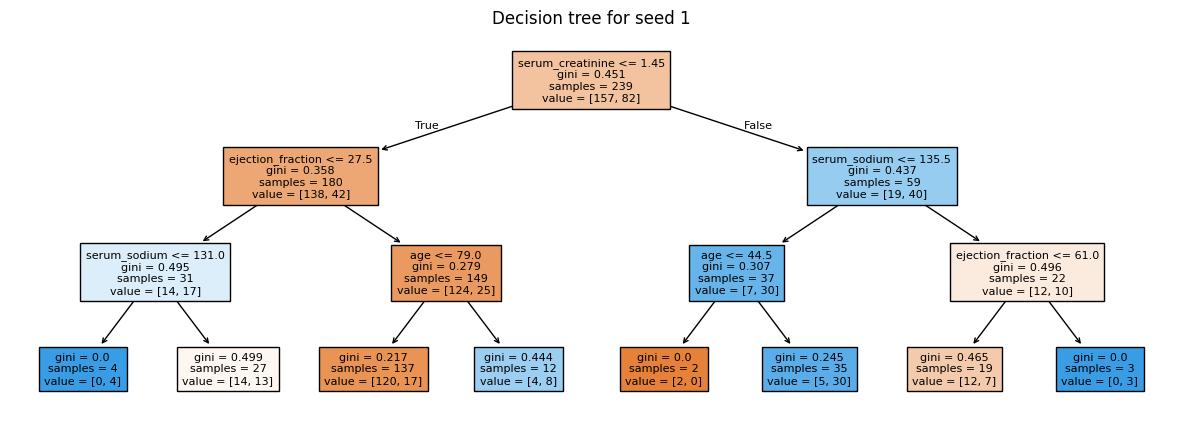

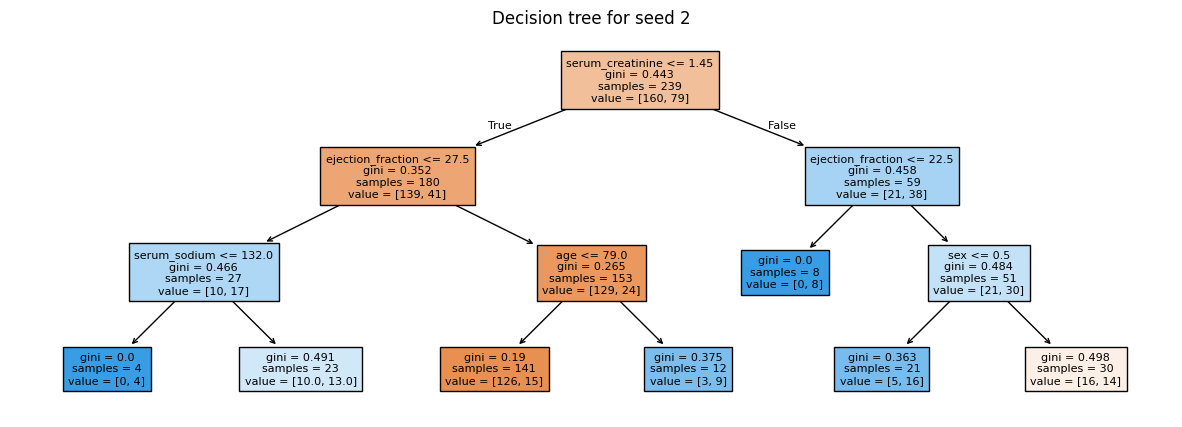

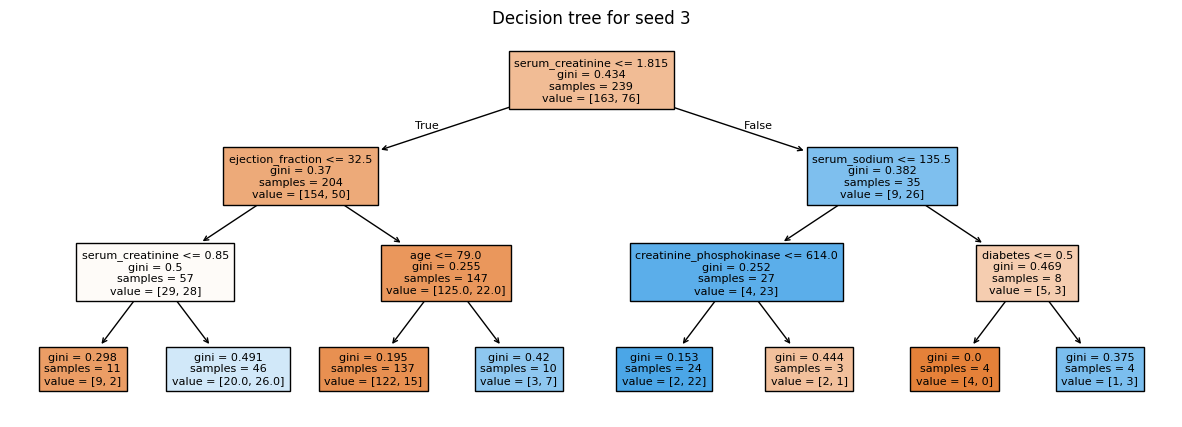

,Tree accuracy (%),Linear accuracy (%)
Seed,,
42,73.3,66.7
1,76.7,80.0
2,75.0,81.7
3,76.7,66.7


,42,1,2,3
age,9.984440e-03,8.360180e-03,8.916850e-03,9.791000e-03
anaemia,4.065809e-02,5.424748e-02,6.246412e-02,4.024140e-03
creatinine_phosphokinase,3.269000e-05,5.398000e-05,6.624000e-05,7.696000e-05
diabetes,2.841084e-02,5.810835e-02,-1.162067e-02,-6.584870e-03
ejection_fraction,-1.032323e-02,-9.974920e-03,-9.656940e-03,-9.929370e-03
high_blood_pressure,6.992924e-02,3.702920e-02,4.477614e-02,6.820250e-02
platelets,-1.500000e-07,-2.600000e-07,-1.500000e-07,-2.000000e-08
serum_creatinine,1.277195e-01,1.145516e-01,1.110636e-01,1.093293e-01
serum_sodium,-8.236590e-03,-1.216894e-02,-9.860710e-03,-1.280425e-02
sex,-9.575169e-02,-5.978601e-02,-8.048512e-02,-5.997680e-02


In [40]:
# Q3

alternative_seeds = [1, 2, 3]

for seed in alternative_seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed
    )
    fit_and_save(seed, X_train, X_test, y_train, y_test)

display(pd.DataFrame(accuracy_by_seed).T.rename_axis("Seed").round(1))
display(pd.DataFrame(coefficients).round(8))

Q3:

All four trees first split on serum creatinine. The cutoff was about 1.815 for seeds 42 and 3 and 1.45 for seeds 1 and 2. Above the cutoff, seed 42 split on serum creatinine again, seeds 1 and 3 used serum sodium, and seed 2 used ejection fraction. The age and ejection fraction coefficients stayed similar across seeds, while the diabetes coefficient changed sign.

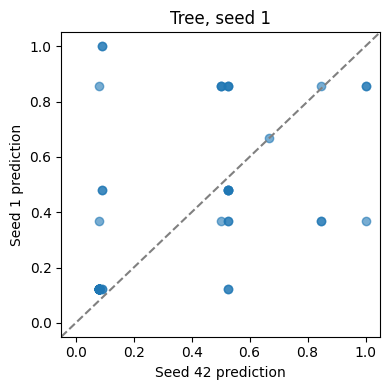

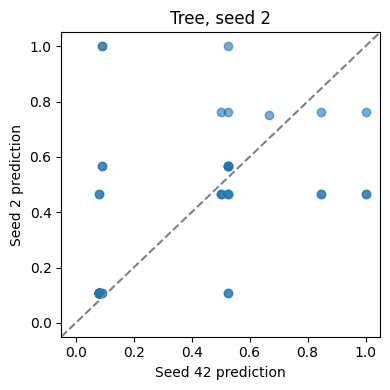

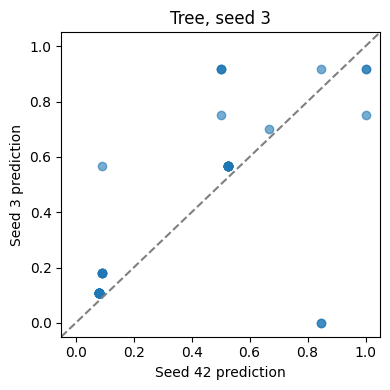

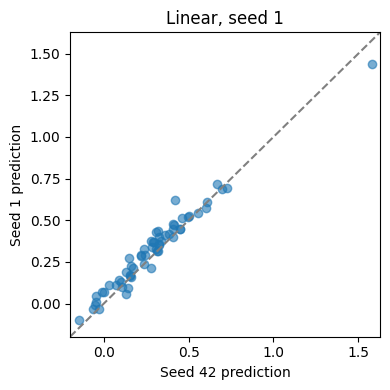

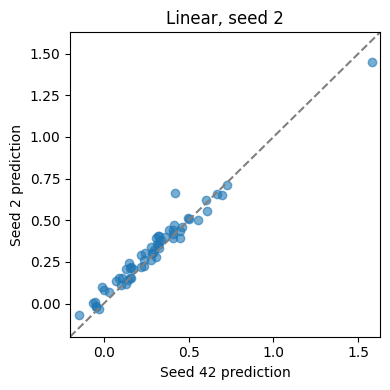

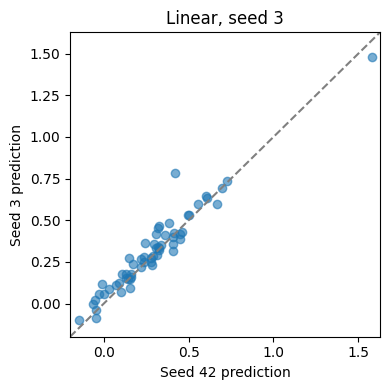

,Model,Alternative seed,Correlation,Intercept,Slope,R-squared,Within 0.10
0,Tree,1,0.567,0.184,0.585,0.322,38
1,Tree,2,0.583,0.169,0.555,0.340,44
2,Tree,3,0.767,0.096,0.775,0.588,52
3,Linear,1,0.980,0.059,0.919,0.961,55
4,Linear,2,0.982,0.058,0.896,0.964,57
5,Linear,3,0.963,0.049,0.929,0.928,52


In [41]:
# Q4

def compare_predictions(scores, model_name):
    baseline = scores[baseline_seed]
    baseline_column = scores[[baseline_seed]]
    low = scores.min().min() - 0.05
    high = scores.max().max() + 0.05
    rows = []

    for seed in alternative_seeds:
        alternative = scores[seed]

        plt.figure(figsize=(4, 4))
        plt.scatter(baseline, alternative, alpha=0.6)
        plt.plot([low, high], [low, high], "--", color="gray")
        plt.xlim(low, high)
        plt.ylim(low, high)
        plt.xlabel("Seed 42 prediction")
        plt.ylabel(f"Seed {seed} prediction")
        plt.title(f"{model_name}, seed {seed}")
        plt.tight_layout()
        plt.show()

        comparison = LinearRegression()
        comparison.fit(baseline_column, alternative)

        rows.append({
            "Model": model_name,
            "Alternative seed": seed,
            "Correlation": baseline.corr(alternative),
            "Intercept": comparison.intercept_,
            "Slope": comparison.coef_[0],
            "R-squared": comparison.score(baseline_column, alternative),
            "Within 0.10": ((alternative - baseline).abs() <= 0.10).sum()
        })

    return rows

tree_results = compare_predictions(tree_scores, "Tree")
linear_results = compare_predictions(linear_scores, "Linear")
display(pd.DataFrame(tree_results + linear_results).round(3))

Each split changes which patients the model learns from. For diabetes, the model estimates a difference between patients with and without diabetes while accounting for the other predictors. Changes in which patients and outcomes are represented in those groups can shift that estimate. Age and ejection fraction had more consistent estimates across the four splits. The size of a coefficient change also depends on the units of the predictor.

Q4a: The linear predictions generally follow the equality line in all three plots. The tree predictions form clusters because patients in the same leaf receive the same score. Many low scores are similar across trees, with several large gaps, especially for seeds 1 and 2.

Q4b: The linear predictions are highly correlated in every comparison. The tree correlations are moderate for seeds 1 and 2 and stronger for seed 3.

Q4c: The linear comparisons have intercepts near zero, slopes fairly close to 1, and R^2 values above 0.92. The positive intercepts and slopes below 1 indicate that the alternative linear predictions tend to be slightly higher at the low end and less spread out. The tree regressions have intercepts farther from zero, slopes farther below 1, and R^2 values well below 1.

Q5.

The linear models were more stable overall. Individual coefficients such as diabetes could shift while the combined predictions stayed close. The trees kept the same first split variable, but changes in its cutoff and the lower branches could send a patient to a leaf with a very different score. For example, one patient's tree score went from 0.091 with seed 42 to 1.000 with seed 1.

Q6.

True. Using a difference of 0.10 or less to describe close agreement, 38-52 of the 60 tree prediction pairs stayed close to the baseline in each comparison, even though the branches changed. For the linear models, 52-57 of the 60 pairs stayed that close. The tree results show how predictions can agree for most patients while still changing sharply for some individuals.  

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [42]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]